## Project Setup

In [2]:
import os
import sys
import time
import tracemalloc
import matplotlib.pyplot as plt
import numpy as np

# Create project directory
project_name = "Lab4_Smart_Optimization"

os.makedirs(project_name, exist_ok=True)

# Create required folders
os.makedirs(project_name + "/screenshots", exist_ok=True)
os.makedirs(project_name + "/reports", exist_ok=True)

print("Project Workspace Created Successfully!")
print("\nPython Version:", sys.version)
print("NumPy Version:", np.__version__)
print("Matplotlib Version:", plt.matplotlib.__version__)
print("\nRequired Libraries Imported Successfully!")

Project Workspace Created Successfully!

Python Version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
NumPy Version: 2.4.6
Matplotlib Version: 3.11.0

Required Libraries Imported Successfully!


## Sequence Analysis using LCS

In [3]:
def LCS(X, Y):
    m = len(X)
    n = len(Y)
    dp = [[0 for j in range(n + 1)] for i in range(m + 1)]
    # Construct DP Table
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if X[i - 1] == Y[j - 1]:
                dp[i][j] = 1 + dp[i - 1][j - 1]
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    # Find LCS
    i = m
    j = n
    result = []
    while i > 0 and j > 0:
        if X[i - 1] == Y[j - 1]:
            result.append(X[i - 1])
            i -= 1
            j -= 1
        elif dp[i - 1][j] >= dp[i][j - 1]:
            i -= 1
        else:
            j -= 1
    result.reverse()
    return dp, ''.join(result)
# Input Sequences
X = "AGGTAB"
Y = "GXTXAYB"
dp, subsequence = LCS(X, Y)
# Display Results
print("Sequence 1:", X)
print("Sequence 2:", Y)
print("\nDP Table:")
for row in dp:
    print(row)
print("\nLongest Common Subsequence:", subsequence)
print("LCS Length:", len(subsequence))
print("\nTime Complexity: O(m*n)")
print("Space Complexity: O(m*n)")

Sequence 1: AGGTAB
Sequence 2: GXTXAYB

DP Table:
[0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 1, 1, 1]
[0, 1, 1, 1, 1, 1, 1, 1]
[0, 1, 1, 1, 1, 1, 1, 1]
[0, 1, 1, 2, 2, 2, 2, 2]
[0, 1, 1, 2, 2, 3, 3, 3]
[0, 1, 1, 2, 2, 3, 3, 4]

Longest Common Subsequence: GTAB
LCS Length: 4

Time Complexity: O(m*n)
Space Complexity: O(m*n)


## 0/1 Knapsack using Dynamic Programming.

In [4]:
def knapsack(weights, profits, capacity):
    n = len(weights)
    dp = [[0 for j in range(capacity + 1)]
          for i in range(n + 1)]
    # Construct DP Table
    for i in range(1, n + 1):
        for w in range(capacity + 1):
            if weights[i - 1] <= w:
                dp[i][w] = max(
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]],
                    dp[i - 1][w]
                )
            else:
                dp[i][w] = dp[i - 1][w]
    # Find Selected Items
    selected_items = []
    w = capacity
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected_items.append(i)
            w -= weights[i - 1]
    selected_items.reverse()
    return dp, selected_items
# Input Data
weights = [2, 3, 4, 5]
profits = [3, 4, 5, 6]
capacity = 5
# Execute Knapsack
dp, selected = knapsack(weights, profits, capacity)
# Display DP Table
print("Knapsack DP Table:")
for row in dp:
    print(row)
# Display Results
print("\nSelected Items:", selected)
print("Maximum Achievable Profit:", dp[len(weights)][capacity])
print("\nTime Complexity: O(n*W)")
print("Space Complexity: O(n*W)")

Knapsack DP Table:
[0, 0, 0, 0, 0, 0]
[0, 0, 3, 3, 3, 3]
[0, 0, 3, 4, 4, 7]
[0, 0, 3, 4, 5, 7]
[0, 0, 3, 4, 5, 7]

Selected Items: [1, 2]
Maximum Achievable Profit: 7

Time Complexity: O(n*W)
Space Complexity: O(n*W)


## Matrix Chain Multiplication

In [5]:
def matrix_chain(p):
    n = len(p) - 1
    dp = [[0 for j in range(n + 1)]
          for i in range(n + 1)]
    split = [[0 for j in range(n + 1)]
             for i in range(n + 1)]
    # Construct Cost Table
    for length in range(2, n + 1):
        for i in range(1, n - length + 2):
            j = i + length - 1
            dp[i][j] = float('inf')
            for k in range(i, j):
                cost = (dp[i][k] +dp[k + 1][j] +p[i - 1] * p[k] * p[j])
                if cost < dp[i][j]:
                    dp[i][j] = cost
                    split[i][j] = k
    # Find Optimal Parenthesization
    def print_order(i, j):
        if i == j:
            return "A" + str(i)
        k = split[i][j]
        return "(" + print_order(i, k) + " x " + print_order(k + 1, j) + ")"
    order = print_order(1, n)
    return dp, split, order
# Input Matrix Dimensions
p = [10, 30, 5, 60]
dp, split, order = matrix_chain(p)
# Display Cost Table
print("Matrix Chain Cost Table:")
for i in range(1, len(p)):
    print(dp[i][1:len(p)])
# Display Parenthesization Table
print("\nParenthesization Table:")
for i in range(1, len(p)):
    print(split[i][1:len(p)])
# Display Results
print("\nOptimal Multiplication Order:", order)
print("Minimum Multiplication Cost:", dp[1][len(p) - 1])
print("\nTime Complexity: O(n^3)")
print("Space Complexity: O(n^2)")

Matrix Chain Cost Table:
[0, 1500, 4500]
[0, 0, 9000]
[0, 0, 0]

Parenthesization Table:
[0, 1, 2]
[0, 0, 2]
[0, 0, 0]

Optimal Multiplication Order: ((A1 x A2) x A3)
Minimum Multiplication Cost: 4500

Time Complexity: O(n^3)
Space Complexity: O(n^2)


## Performance Analysis

In [7]:
import time
import tracemalloc
def measure_performance(algorithm, *args):
    tracemalloc.start()
    start_time = time.perf_counter()
    result = algorithm(*args)
    end_time = time.perf_counter()
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    execution_time = (end_time - start_time) * 1000
    memory_usage = peak / 1024
    return result, execution_time, memory_usage
# LCS Performance
X = "AGGTAB"
Y = "GXTXAYB"
lcs_result, lcs_time, lcs_memory = measure_performance(LCS, X, Y)
# Knapsack Performance
weights = [2, 3, 4, 5]
profits = [3, 4, 5, 6]
capacity = 5
knapsack_result, knapsack_time, knapsack_memory = measure_performance(knapsack, weights, profits, capacity)
# Matrix Chain Performance
p = [10, 30, 5, 60]
matrix_result, matrix_time, matrix_memory = measure_performance(matrix_chain, p)
# Number of Subproblems
lcs_subproblems = (len(X) + 1) * (len(Y) + 1)
knapsack_subproblems = (
    (len(weights) + 1) * (capacity + 1)
)
n = len(p) - 1
matrix_subproblems = n * (n + 1) // 2
# Performance Comparison
print("PERFORMANCE ANALYSIS")
print("-" * 85)
print("{:<25} {:<15} {:<15} {:<15}".format("Algorithm", "Time (ms)", "Memory (KB)", "Subproblems"))
print("-" * 85)
print("{:<25} {:<15.4f} {:<15.2f} {:<15}".format("LCS", lcs_time, lcs_memory, lcs_subproblems))
print("{:<25} {:<15.4f} {:<15.2f} {:<15}".format("0/1 Knapsack", knapsack_time, knapsack_memory,knapsack_subproblems))
print("{:<25} {:<15.4f} {:<15.2f} {:<15}".format(
    "Matrix Chain", matrix_time, matrix_memory,matrix_subproblems))
# Complexity Comparison
print("\nCOMPLEXITY COMPARISON")
print("-" * 65)
print("{:<25} {:<18} {:<18}".format("Algorithm", "Time Complexity", "Space Complexity"))
print("-" * 65)
print("{:<25} {:<18} {:<18}".format("LCS", "O(m*n)", "O(m*n)"))
print("{:<25} {:<18} {:<18}".format("0/1 Knapsack", "O(n*W)", "O(n*W)"))
print("{:<25} {:<18} {:<18}".format("Matrix Chain", "O(n^3)", "O(n^2)"))

PERFORMANCE ANALYSIS
-------------------------------------------------------------------------------------
Algorithm                 Time (ms)       Memory (KB)     Subproblems    
-------------------------------------------------------------------------------------
LCS                       0.1380          0.58            56             
0/1 Knapsack              0.0779          0.46            30             
Matrix Chain              0.1408          0.92            6              

COMPLEXITY COMPARISON
-----------------------------------------------------------------
Algorithm                 Time Complexity    Space Complexity  
-----------------------------------------------------------------
LCS                       O(m*n)             O(m*n)            
0/1 Knapsack              O(n*W)             O(n*W)            
Matrix Chain              O(n^3)             O(n^2)            


## Visualization of DP Tables and Performance Statistics.

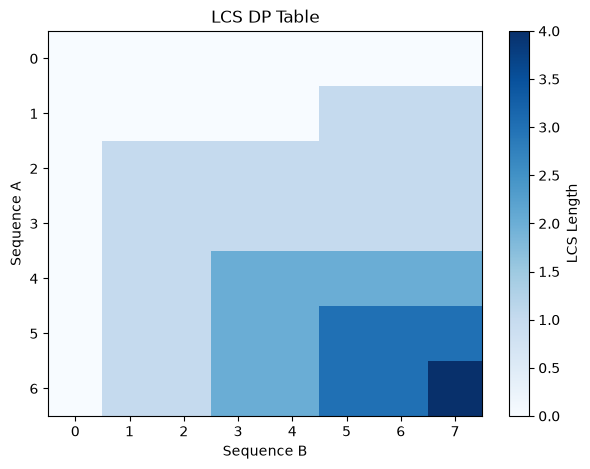

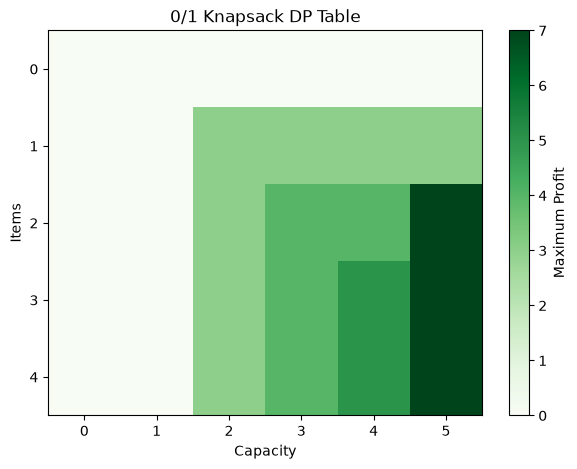

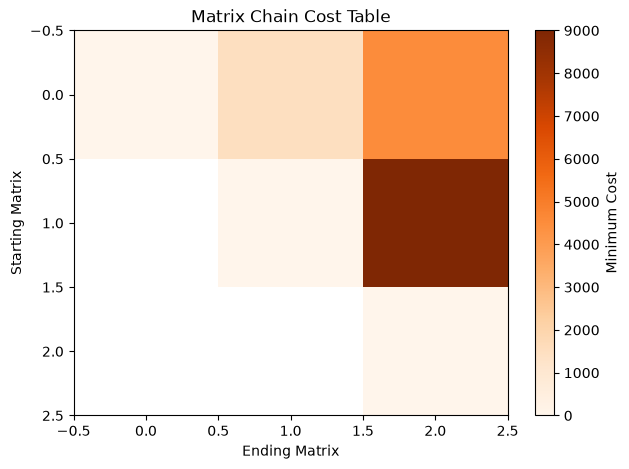

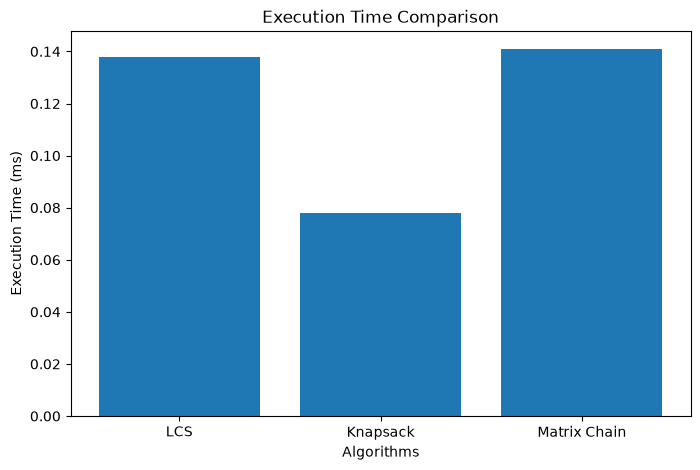

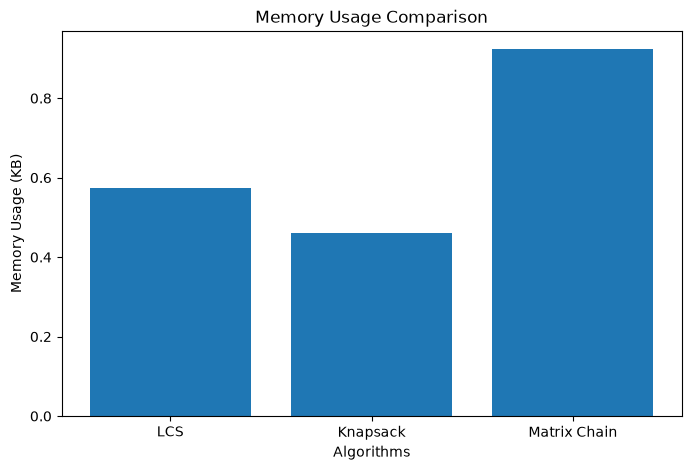

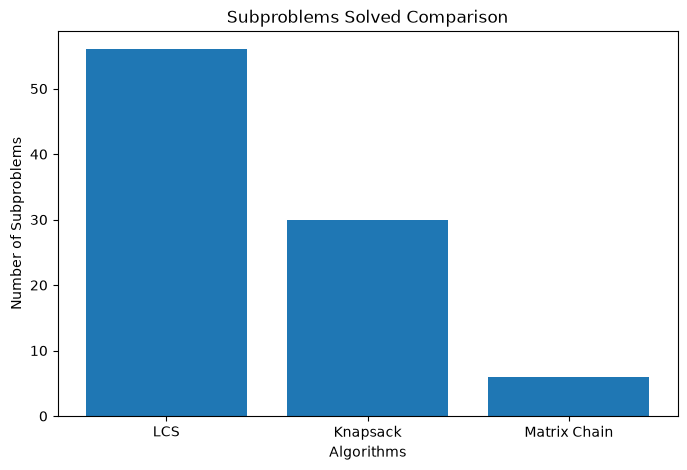

All Visualizations Generated Successfully!


In [8]:
import matplotlib.pyplot as plt
import numpy as np
# Get DP Tables
lcs_table = LCS("AGGTAB", "GXTXAYB")[0]
knapsack_table = knapsack(
    [2, 3, 4, 5],
    [3, 4, 5, 6],
    5
)[0]
matrix_table = matrix_chain([10, 30, 5, 60])[0]
# 1. LCS DP Table Visualization
plt.figure(figsize=(7, 5))
plt.imshow(lcs_table, cmap="Blues", aspect="auto")
plt.colorbar(label="LCS Length")
plt.title("LCS DP Table")
plt.xlabel("Sequence B")
plt.ylabel("Sequence A")
plt.show()

# 2. Knapsack DP Table Visualization

plt.figure(figsize=(7, 5))

plt.imshow(knapsack_table, cmap="Greens", aspect="auto")
plt.colorbar(label="Maximum Profit")

plt.title("0/1 Knapsack DP Table")
plt.xlabel("Capacity")
plt.ylabel("Items")

plt.show()


# 3. Matrix Chain Cost Table Visualization

matrix_values = np.array([
    [matrix_table[i][j] if j >= i else np.nan
     for j in range(1, len(matrix_table))]
    for i in range(1, len(matrix_table))
])

plt.figure(figsize=(7, 5))

plt.imshow(matrix_values, cmap="Oranges", aspect="auto")
plt.colorbar(label="Minimum Cost")

plt.title("Matrix Chain Cost Table")
plt.xlabel("Ending Matrix")
plt.ylabel("Starting Matrix")

plt.show()


# 4. Execution Time Comparison

algorithms = ["LCS", "Knapsack", "Matrix Chain"]

execution_times = [
    lcs_time,
    knapsack_time,
    matrix_time
]

plt.figure(figsize=(8, 5))

plt.bar(algorithms, execution_times)

plt.title("Execution Time Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Execution Time (ms)")

plt.show()


# 5. Memory Usage Comparison

memory_values = [
    lcs_memory,
    knapsack_memory,
    matrix_memory
]

plt.figure(figsize=(8, 5))

plt.bar(algorithms, memory_values)

plt.title("Memory Usage Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Memory Usage (KB)")

plt.show()


# 6. Number of Subproblems Comparison

subproblems = [
    lcs_subproblems,
    knapsack_subproblems,
    matrix_subproblems
]

plt.figure(figsize=(8, 5))

plt.bar(algorithms, subproblems)

plt.title("Subproblems Solved Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Number of Subproblems")

plt.show()

print("All Visualizations Generated Successfully!")